# Random Forest: German Credit
DSE4212/QF4212 Group Project 1

Convention used everywhere: **positive class (1) = default / bad credit**.
Same split, preprocessing pipeline, CV scheme, threshold rules and `evaluate()` as the logistic
regression notebook, so the three models are directly comparable.

- Part 1: Method and untuned reference model
- Part 2: Hyperparameter tuning (cross-validation on training data only)
- Part 3: Operating points (thresholds from out-of-fold predictions)
- Part 4: Test-set evaluation
- Part 5: Interpretation (permutation importance)
- Part 6: Save model, probabilities and metrics

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

# Find the project root (the folder that contains src/) so `from src...` works
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocessing import make_pipeline, check_inputs   # shared preprocessing
from src.evaluation import (evaluate, metrics_only, results_table,
                            f1_optimal_threshold, cost_min_threshold,
                            cost_optimal_threshold, bootstrap_auc_ci, RANDOM_STATE)

matplotlib.rcParams.update({'font.size': 12})

# Output folders
OUT = ROOT / "outputs"
for sub in ("models", "predictions", "results"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# Settings (identical to the logistic regression notebook)
TARGET = "credit_risk"   # 1 = default (bad), 0 = good
FN_COST = 5              # a missed default costs 5x a wrongly rejected good client

## Load data
The team's fixed `train.csv` / `test.csv` split (800 / 200 rows, stratified, seed 4212), so this model is trained and tested on exactly the same rows as logistic regression.

In [2]:
train = pd.read_csv(OUT / "train.csv")
test = pd.read_csv(OUT / "test.csv")

y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)
X_train, X_test = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])

print("train:", X_train.shape, "| test:", X_test.shape)
print(f"Default rate: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
check_inputs(X_train)   # raises if expected columns are missing

train: (800, 26) | test: (200, 26)
Default rate: train 0.300, test 0.300


## Part 1: Method and untuned reference model
**Random forest.** An average of many deep decision trees, each grown on a bootstrap sample of the
rows and choosing each split from a random subset of the features. Averaging de-correlated trees
reduces variance, and the trees capture non-linear effects and interactions (e.g. large loan *and*
no savings) without having to specify them.

**Preprocessing.** The shared `make_pipeline` (engineered features, one-hot encoding, imputation)
with `scale_numeric=False`: tree splits are unaffected by monotone rescaling, so scaling would
add nothing. Sensitive attributes (`gender_group`, `age_group`) are not model inputs.

**Class imbalance (30% defaults)** is handled at two levels:
1. *Training:* `class_weight="balanced_subsample"` reweights the classes inside each bootstrap
   sample so defaults carry ~2.3× the weight of good clients. Whether this helps is treated as a
   tuning choice (vs. `None`) and decided by CV.
2. *Decision:* the classification threshold is chosen to minimise the 5:1 misclassification cost
   on out-of-fold training predictions (Part 3). This is what drives recall on defaults.

The reference model below is scikit-learn's default forest (500 trees, fully grown, no weighting).

In [3]:
rf_default = make_pipeline(RandomForestClassifier(n_estimators=500, n_jobs=-1,
                                                  random_state=RANDOM_STATE),
                           scale_numeric=False)
rf_default.fit(X_train, y_train)
res_default = evaluate(rf_default, X_test, y_test, name="RF untuned (500 trees)", fn_cost=FN_COST)

=== RF untuned (500 trees) | threshold = 0.500 ===
AUC 0.8082 | Precision 0.7436 | Recall 0.4833 | F1 0.5859 | Accuracy 0.7950
          pred 0  pred 1
actual 0     130      10
actual 1      31      29


## Part 2: Hyperparameter tuning (training data only)
`RepeatedStratifiedKFold` (5 folds × 2 repeats, seed 4212), scored on ROC AUC, the same as for logistic
regression. Each fold keeps the 70/30 class ratio and, with 640 training rows per fold, has
~190 defaults, enough for a stable AUC. The repeat reduces the noise from a single split.

The number of trees is fixed at 500: more trees never hurt a forest, they only reduce the noise.
The grid controls the complexity of each tree and the randomness between trees:

| Parameter | Values | Role |
|---|---|---|
| `max_depth` | 4, 6, 8, 12, None | tree depth (None = grow fully) |
| `min_samples_leaf` | 1, 3, 5, 10 | smallest allowed leaf; larger = smoother probabilities |
| `max_features` | sqrt, 0.33 | share of features tried at each split |
| `class_weight` | None, balanced_subsample | class-imbalance reweighting |

80 combinations × 10 fits = 800 forests. `return_train_score=True` is used to check overfitting.

In [4]:
base = make_pipeline(RandomForestClassifier(n_estimators=500, n_jobs=1, random_state=RANDOM_STATE),
                     scale_numeric=False)
param_grid = {
    "classifier__max_depth": [4, 6, 8, 12, None],
    "classifier__min_samples_leaf": [1, 3, 5, 10],
    "classifier__max_features": ["sqrt", 0.33],
    "classifier__class_weight": [None, "balanced_subsample"],
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
gs = GridSearchCV(base, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True,
                  return_train_score=True)

t0 = time.time()
gs.fit(X_train, y_train)
print(f"Grid search took {time.time() - t0:.0f}s")

best = gs.best_estimator_
cvr = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
cv_std = cvr.iloc[0]["std_test_score"]
cv_train = cvr.iloc[0]["mean_train_score"]

print(f"Best params: {gs.best_params_}")
print(f"CV AUC: {gs.best_score_:.4f} (+/- {cv_std:.4f}) | mean train-fold AUC {cv_train:.4f}")
cols = ["param_classifier__max_depth", "param_classifier__min_samples_leaf",
        "param_classifier__max_features", "param_classifier__class_weight",
        "mean_test_score", "std_test_score", "mean_train_score"]
cvr[cols].head(10)

Grid search took 92s
Best params: {'classifier__class_weight': 'balanced_subsample', 'classifier__max_depth': 8, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1}
CV AUC: 0.7888 (+/- 0.0374) | mean train-fold AUC 0.9909


,param_classifier__max_depth,param_classifier__min_samples_leaf,param_classifier__max_features,param_classifier__class_weight,mean_test_score,std_test_score,mean_train_score
56,8,1,sqrt,balanced_subsample,0.788839,0.037353,0.990939
16,8,1,sqrt,None,0.788542,0.035113,0.989655
64,12,1,sqrt,balanced_subsample,0.788337,0.036960,0.999997
24,12,1,sqrt,None,0.785584,0.034214,0.999997
72,None,1,sqrt,balanced_subsample,0.785472,0.038981,1.000000
57,8,3,sqrt,balanced_subsample,0.785156,0.037221,0.970716
9,6,3,sqrt,None,0.784542,0.034022,0.929800
65,12,3,sqrt,balanced_subsample,0.784431,0.037290,0.990083
68,12,1,0.33,balanced_subsample,0.783854,0.042513,1.000000
8,6,1,sqrt,None,0.783836,0.034907,0.952302


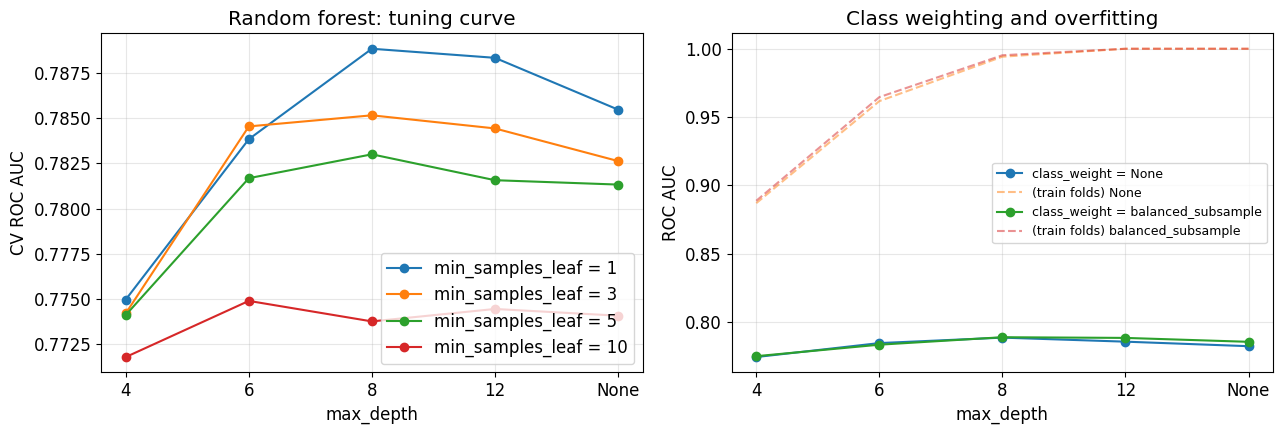

,best CV AUC,mean CV AUC over grid
weight,,
None,0.788542,0.775127
balanced_subsample,0.788839,0.777404


In [5]:
# CV AUC vs depth (best over the other parameters), and the effect of class weighting
cvr["depth"] = cvr["param_classifier__max_depth"].apply(lambda d: "None" if d is None or pd.isna(d) else str(int(d)))
cvr["weight"] = cvr["param_classifier__class_weight"].apply(lambda w: "balanced_subsample" if w == "balanced_subsample" else "None")
depth_order = ["4", "6", "8", "12", "None"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for leaf, g in cvr.groupby("param_classifier__min_samples_leaf"):
    s = g.groupby("depth")["mean_test_score"].max().reindex(depth_order)
    axes[0].plot(depth_order, s.values, marker="o", label=f"min_samples_leaf = {leaf}")
axes[0].set(xlabel="max_depth", ylabel="CV ROC AUC", title="Random forest: tuning curve")
axes[0].grid(alpha=0.3); axes[0].legend()

for w, g in cvr.groupby("weight"):
    s = g.groupby("depth")["mean_test_score"].max().reindex(depth_order)
    axes[1].plot(depth_order, s.values, marker="o", label=f"class_weight = {w}")
    s_tr = g.groupby("depth")["mean_train_score"].max().reindex(depth_order)
    axes[1].plot(depth_order, s_tr.values, ls="--", alpha=0.5, label=f"(train folds) {w}")
axes[1].set(xlabel="max_depth", ylabel="ROC AUC", title="Class weighting and overfitting")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/rf_tuning_curve.png", dpi=200)
plt.show()

cvr.groupby("weight")["mean_test_score"].agg(["max", "mean"]).rename(
    columns={"max": "best CV AUC", "mean": "mean CV AUC over grid"})

**Remark.** The best forest uses trees of depth 8, leaves of 1 row, √p features per split and
`balanced_subsample` weighting (CV AUC 0.789 ± 0.037). The tuning surface is flat. The top 10 settings are
within 0.005 AUC of each other, well inside one CV standard deviation, so the exact choice matters little.
Very shallow trees (depth 4) and large leaves (10) underfit. Train-fold AUC is ≈ 0.99, so each forest almost memorises its
training rows. This is normal for random forests, and CV AUC is the honest measure.

**Class weighting barely changes the AUC** (best 0.7888 weighted vs 0.7885 unweighted). This is expected.
Reweighting shifts the predicted probabilities upwards but hardly changes how borrowers are *ranked*.
Its practical effect is on the probability scale, which the threshold in Part 3 handles in either case.

## Part 3: Operating points (thresholds)
As for logistic regression, the threshold is chosen from **out-of-fold training predictions** (5-fold stratified CV of the tuned pipeline), never from the test set:

- 0.5, the default
- the F1-optimal threshold
- the cost-optimal threshold, minimising `FN_COST`·FN + FP on the training folds

In [6]:
oof = cross_val_predict(best, X_train, y_train, method="predict_proba",
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))[:, 1]
pd.DataFrame({"index": X_train.index, "y_true": y_train.values, "y_proba": oof}).to_csv(
    OUT / "predictions/rf_train_oof_proba.csv", index=False)

t_f1 = f1_optimal_threshold(y_train, oof)
t_cost = cost_min_threshold(y_train, oof, cost_fn=FN_COST)
print(f"F1-optimal threshold: {t_f1:.3f} | cost-optimal threshold (FN:FP = {FN_COST}:1): {t_cost:.3f} "
      f"(theory for perfectly calibrated probabilities: {cost_optimal_threshold(FN_COST):.3f})")

F1-optimal threshold: 0.379 | cost-optimal threshold (FN:FP = 5:1): 0.274 (theory for perfectly calibrated probabilities: 0.167)


## Part 4: Test-set evaluation
The test set is used once, here. Test-set probabilities are saved to `outputs/predictions/rf_test_proba.csv` (same format as `logreg_test_proba.csv`).

In [7]:
res_05 = evaluate(best, X_test, y_test, threshold=0.5, name="RF tuned @ 0.5", fn_cost=FN_COST,
                  save_to=str(OUT / "predictions/rf_test_proba.csv"))
res_f1 = evaluate(best, X_test, y_test, threshold=t_f1, name="RF tuned @ F1-optimal", fn_cost=FN_COST)
res_cost = evaluate(best, X_test, y_test, threshold=t_cost, name="RF tuned @ cost-optimal", fn_cost=FN_COST)

ci = bootstrap_auc_ci(y_test, res_05["y_proba"])
print(f"\nTest AUC = {res_05['auc']:.3f}, 95% bootstrap CI [{ci[0]:.3f}, {ci[1]:.3f}]")

=== RF tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8026 | Precision 0.6316 | Recall 0.6000 | F1 0.6154 | Accuracy 0.7750
          pred 0  pred 1
actual 0     119      21
actual 1      24      36
=== RF tuned @ F1-optimal | threshold = 0.379 ===
AUC 0.8026 | Precision 0.5000 | Recall 0.7333 | F1 0.5946 | Accuracy 0.7000
          pred 0  pred 1
actual 0      96      44
actual 1      16      44
=== RF tuned @ cost-optimal | threshold = 0.274 ===
AUC 0.8026 | Precision 0.4264 | Recall 0.9167 | F1 0.5820 | Accuracy 0.6050
          pred 0  pred 1
actual 0      66      74
actual 1       5      55



Test AUC = 0.803, 95% bootstrap CI [0.733, 0.870]


In [8]:
table = results_table([res_default, res_05, res_f1, res_cost], fn_cost=FN_COST)
table.to_csv(OUT / "results/rf_results_table.csv", index=False)
table

,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,RF untuned (500 trees),0.500,0.808,0.744,0.483,0.586,0.795,130/10/31/29,165.0
1,RF tuned @ 0.5,0.500,0.803,0.632,0.600,0.615,0.775,119/21/24/36,141.0
2,RF tuned @ F1-optimal,0.379,0.803,0.500,0.733,0.595,0.700,96/44/16/44,124.0
3,RF tuned @ cost-optimal,0.274,0.803,0.426,0.917,0.582,0.605,66/74/5/55,99.0


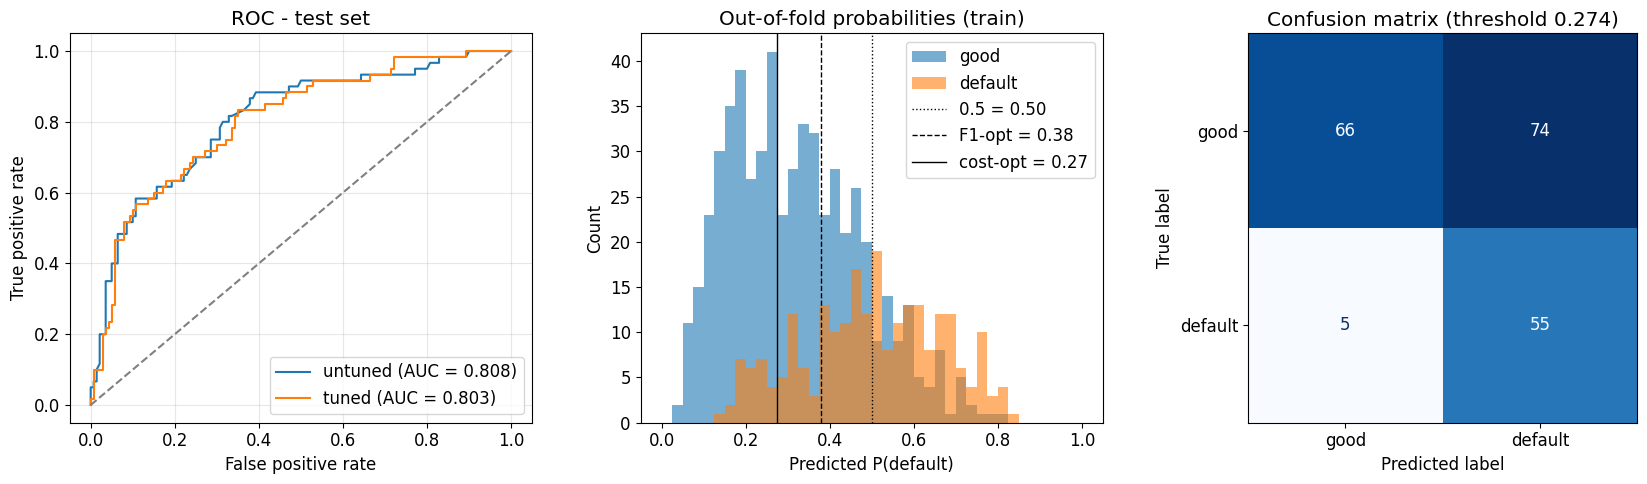

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ROC curves on the test set
for res, lab in [(res_default, "untuned"), (res_05, "tuned")]:
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    axes[0].plot(fpr, tpr, label=f"{lab} (AUC = {res['auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC - test set")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

# Distribution of predicted probabilities (out-of-fold, training set)
bins = np.linspace(0, 1, 41)
axes[1].hist(oof[y_train == 0], bins=bins, alpha=0.6, label="good")
axes[1].hist(oof[y_train == 1], bins=bins, alpha=0.6, label="default")
for t, ls, lab in [(0.5, ":", "0.5"), (t_f1, "--", "F1-opt"), (t_cost, "-", "cost-opt")]:
    axes[1].axvline(t, color="k", ls=ls, lw=1, label=f"{lab} = {t:.2f}")
axes[1].set(xlabel="Predicted P(default)", ylabel="Count", title="Out-of-fold probabilities (train)")
axes[1].legend()

# Confusion matrix at the cost-optimal threshold
ConfusionMatrixDisplay(res_cost["confusion_matrix"], display_labels=["good", "default"]).plot(
    ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title(f"Confusion matrix (threshold {t_cost:.3f})")

plt.tight_layout()
plt.savefig(OUT / "results/rf_roc_confusion.png", dpi=200)
plt.show()

**Remark.** Test AUC is 0.803 (95% CI 0.733–0.870), slightly below the untuned forest's 0.808.
With 200 test rows a 0.005 gap is noise. The tuned model was chosen on CV AUC, which is more reliable.
At 0.5 the tuned forest already catches more defaults than the untuned one (recall 0.60 vs 0.48)
because class weighting raises the predicted probabilities.

The cost-optimal threshold learned on the training folds is 0.274. That is above the 1/6 ≈ 0.167 that theory gives for calibrated
probabilities, because the forest's probabilities are neither calibrated nor on the unweighted scale.
At this threshold the forest catches **55 of 60 defaulters (recall 0.92)** and rejects 74 of 140 good clients.
The misclassification cost is **99**, down from 141 at 0.5.

## Part 5: Interpretation (permutation importance)
Tree ensembles have no coefficients. **Permutation importance** measures how much the test AUC drops when one *original* input column is shuffled (20 repeats). Shuffling a raw column also breaks every one-hot dummy and engineered flag built from it, so the importance of a categorical variable is reported once, not split across its dummies. It shows what the model relies on, not causal effects, and correlated columns can share credit.

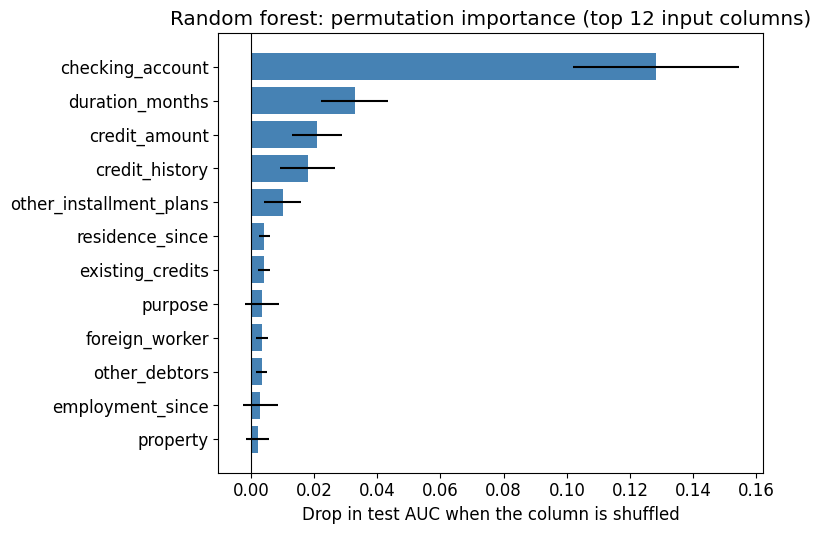

,feature,auc_drop_mean,auc_drop_std
0,checking_account,0.128077,0.026233
1,duration_months,0.032810,0.010590
2,credit_amount,0.020863,0.007891
3,credit_history,0.018042,0.008665
4,other_installment_plans,0.010042,0.005973
5,residence_since,0.004321,0.001608
6,existing_credits,0.004226,0.001811
7,purpose,0.003542,0.005526
8,foreign_worker,0.003452,0.001950
9,other_debtors,0.003393,0.001852


In [10]:
# Columns the pipeline does not use get exactly zero importance and are dropped below
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pi = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_test.columns, "auc_drop_mean": pi.importances_mean,
                     "auc_drop_std": pi.importances_std})
       .query("auc_drop_mean != 0 or auc_drop_std != 0")
       .sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))
imp.to_csv(OUT / "results/rf_permutation_importance.csv", index=False)

top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top["feature"], top["auc_drop_mean"], xerr=top["auc_drop_std"], color="steelblue")
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Drop in test AUC when the column is shuffled")
plt.title("Random forest: permutation importance (top 12 input columns)")
plt.tight_layout()
plt.savefig(OUT / "results/rf_importance.png", dpi=200)
plt.show()
imp.head(12)

**Remark.** The forest relies most on `checking_account` (shuffling it costs 0.13 AUC). Next come loan
`duration_months`, `credit_amount`, `credit_history` and `other_installment_plans`. Below the top five the
mean drops are about the size of their standard deviations, so those columns cannot be ranked reliably.

## Part 6: Save model, probabilities and metrics

In [11]:
joblib.dump(best, OUT / "models/rf_best.joblib")

summary = {
    "model": "RandomForestClassifier",
    "best_params": {k.replace("classifier__", ""): (v if isinstance(v, (str, int, type(None))) else float(v))
                    for k, v in gs.best_params_.items()},
    "n_estimators": 500,
    "cv_auc_mean": float(gs.best_score_), "cv_auc_std": float(cv_std),
    "cv_train_auc_mean": float(cv_train),
    "test_auc_ci95": ci, "fn_cost": FN_COST,
    "thresholds": {"default": 0.5, "f1_opt": t_f1, "cost_opt": t_cost},
    "results": {r["name"]: metrics_only(r) for r in (res_default, res_05, res_f1, res_cost)},
}
(OUT / "results/rf_metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved to", OUT)

Saved to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs
